In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
df=pd.read_csv('insurance.csv')

In [3]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [5]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [6]:
df["smoker"].value_counts()

smoker
no     1064
yes     274
Name: count, dtype: int64

In [7]:
df["sex"].value_counts()

sex
male      676
female    662
Name: count, dtype: int64

In [8]:
df["region"].value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

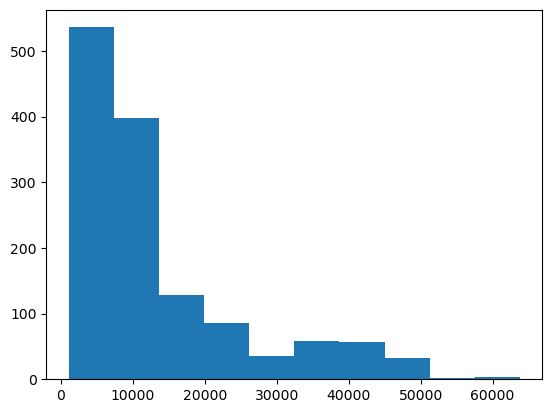

In [9]:
plt.hist(df["charges"])
plt.show()

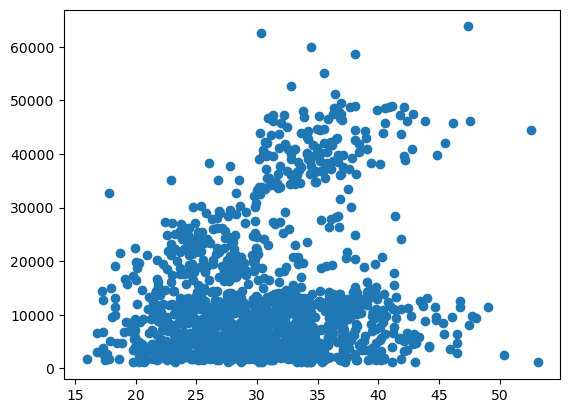

In [10]:
plt.scatter(df["bmi"],df["charges"])
plt.show()

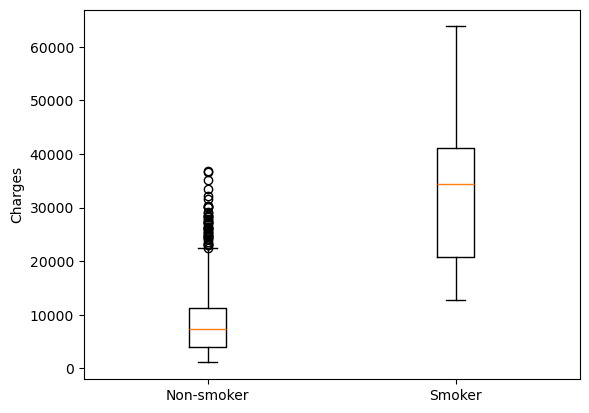

In [11]:
plt.boxplot([
    df[df["smoker"] == "no"]["charges"],
    df[df["smoker"] == "yes"]["charges"]
])

plt.xticks([1, 2], ["Non-smoker", "Smoker"])
plt.ylabel("Charges")
plt.show()

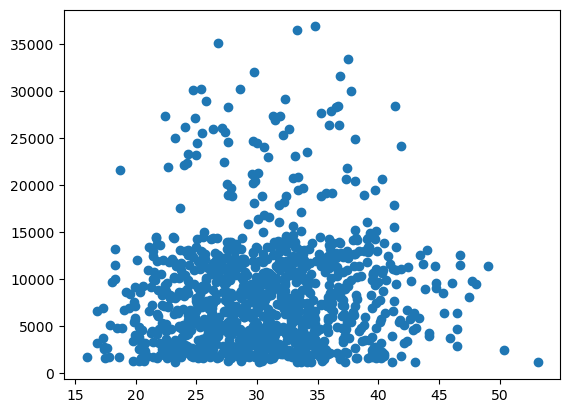

In [12]:
non_smokers = df[df["smoker"] == "no"]

plt.scatter(non_smokers["bmi"], non_smokers["charges"])
plt.show()

In [13]:
df["bmi"].corr(df["charges"])

np.float64(0.19834096883362884)

In [14]:
df["age"].corr(df["charges"])

np.float64(0.2990081933306476)

In [15]:
corr=df[["age", "bmi", "children", "charges"]].corr()

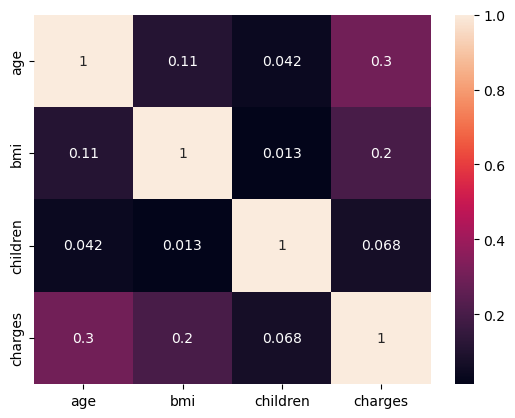

In [16]:
sns.heatmap(corr, annot=True)
plt.show()

In [17]:
X = df[["age", "sex", "bmi", "children", "smoker", "region"]]
y = df["charges"]

In [18]:
X.head()

,age,sex,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest


In [19]:
y.head()

0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64

In [20]:
from sklearn.model_selection import train_test_split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [22]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1070, 6), (268, 6), (1070,), (268,))

In [23]:
numerical_cols = ["age","bmi","children"]
categorical_cols = ["sex","smoker","region"]

In [24]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

In [25]:
preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(drop="first"), categorical_cols)
], remainder="passthrough")

In [26]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [27]:
X_train_processed.shape, X_test_processed.shape

((1070, 8), (268, 8))

In [28]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()

In [29]:
model.fit(X_train_processed, y_train)

LinearRegression()

In [30]:
model.coef_

array([-1.85916916e+01,  2.36511289e+04, -3.70677326e+02, -6.57864297e+02,
       -8.09799354e+02,  2.56975706e+02,  3.37092552e+02,  4.25278784e+02])

In [31]:
preprocessor.get_feature_names_out()

array(['categorical__sex_male', 'categorical__smoker_yes',
       'categorical__region_northwest', 'categorical__region_southeast',
       'categorical__region_southwest', 'remainder__age',
       'remainder__bmi', 'remainder__children'], dtype=object)

In [32]:
y_pred = model.predict(X_test_processed)

In [33]:
y_pred[:10]

array([ 8969.55027444,  7068.74744287, 36858.41091155,  9454.67850053,
       26973.17345656, 10864.11316424,   170.28084136, 16903.45028662,
        1092.43093614, 11218.34318352])

In [34]:
y_test.iloc[0], y_pred[0]

(np.float64(9095.06825), np.float64(8969.550274436146))

In [35]:
from sklearn.metrics import mean_absolute_error

In [36]:
mae = mean_absolute_error(y_test,y_pred)

In [37]:
mae

4181.1944737536605

In [38]:
from sklearn.metrics import mean_squared_error

In [39]:
mse = mean_squared_error(y_test,y_pred)

In [40]:
mse

33596915.851361506

In [41]:
rmse = np.sqrt(mse)

In [42]:
rmse

np.float64(5796.284659276277)

In [43]:
from sklearn.metrics import r2_score

In [44]:
r2 = r2_score(y_test,y_pred)

In [45]:
r2

0.7835929767120721

In [46]:
residuals = y_test - y_pred

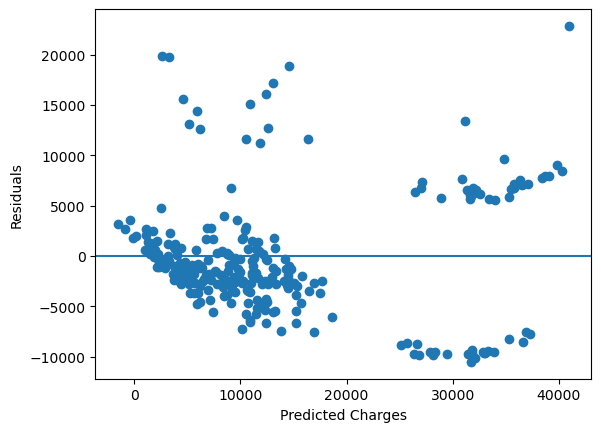

In [47]:
plt.scatter(y_pred, residuals)
plt.axhline(0)
plt.xlabel("Predicted Charges")
plt.ylabel("Residuals")
plt.show()